In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta, date
import matplotlib.dates as mdates

plt.rcParams.update({'font.size':14})
plt.rcParams['axes.xmargin'] = 0
plt.rcParams['axes.ymargin'] = 0

def remove_spines(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

alpha = 0.1


# Important dates
currentYTD_grace   = (8, 31)   # Goes through Sept 15 actually       # (7, 16)   # July 16
currentYTD_is      = (7, 2)    # July 2

mb_start_month = 9
mb_start_day   = 1

startdate = datetime(2025, 9, 1)
enddate = datetime(2026, 8, 31)

Matplotlib is building the font cache; this may take a moment.


In [6]:
# Load data

# GRACE
scaling = 0.84          # to exclude peripheral ice
# grace_data = pd.read_csv('GrIS_graceJPLrl0603_c20c30GSFCtn14_giaICE6GD_geocJPLtn13_200204_202607.txt', comment='#')
grace_data = pd.read_csv('tmb/GrIS_graceJPLrl0603_c20c30GSFCtn14_giaICE6GD_geocJPLtn13_200204_202609.txt', comment='#')
decyr = grace_data.iloc[:, 0].values
gdate = np.array([datetime(int(y), 1, 1) + timedelta(days=(y - int(y)) * (datetime(int(y) + 1, 1, 1) - datetime(int(y), 1, 1)).days) for y in decyr])
gmb = grace_data.iloc[:,1].values
gmb = gmb * scaling
print('first day of GRACE data: ', gdate[0].strftime("%B %d, %Y"))
print('last date of GRACE data: ', gdate[-1].strftime("%B %d, %Y"))
# Zero it on September 1, 2025
gmb0 = np.interp(startdate.toordinal(), np.array([d.toordinal() for d in gdate]), gmb, left=None, right=None, period=None)
gmb = gmb - gmb0
# GRACE errors
g_err_leak = scaling * grace_data.iloc[:, 3]
g_err_noleak = scaling * grace_data.iloc[:,2]

# ICESat-2
is_data = np.loadtxt('tmb/smith/delta_m_monthly_WRT_2019.67_09232026.csv', delimiter=',', comments='%') # This has all the data from 2019-2026
doy_is = (is_data[:, 0] - 2019) * 365.2425 
IS_date = np.array([datetime(2019, 1, 1) + timedelta(days=int(day)) for day in doy_is]) 
IS_mb = is_data[:, 1]
IS_err = is_data[:, 2]
print('first day of ICESat-2 data: ', IS_date[0].strftime("%B %d, %Y"))
print('last date of ICESat-2 data: ', IS_date[-1].strftime("%B %d, %Y"))
# Zero it on September 1, 2025
ismb0 = np.interp(startdate.toordinal(), np.array([d.toordinal() for d in IS_date]), IS_mb, left=None, right=None, period=None)
IS_mb = IS_mb - ismb0

first day of GRACE data:  April 17, 2002
last date of GRACE data:  September 15, 2026
first day of ICESat-2 data:  September 01, 2019
last date of ICESat-2 data:  July 02, 2026


In [7]:
from datetime import datetime
import numpy as np

def interp_mb(timeline, dates, mb, err=None):
    """
    Interpolate a cumulative mass-balance series onto a timeline.
    """

    x = np.array([d.toordinal() for d in dates])
    xi = np.array([d.toordinal() for d in timeline])

    mbi = np.interp(xi, x, mb, right=np.nan)
    mbi = mbi - mbi[0]

    if err is None:
        return mbi

    erri = np.interp(xi, x, err, right=np.nan)

    return mbi, erri


def mb_year_timeline(year, end_month, end_day, report_day):
    """
    Mass balance year:
        Sep 1 (year-1)
        ...
        end_month/end_day (year)
    """

    t0 = datetime(year - 1, 9, 1)
    t1 = datetime(year, end_month, end_day)

    timeline = [t0]
    d = t0

    while d < t1:

        timeline.append(d.replace(day=report_day))

        if d.month == 12:
            d = d.replace(year=d.year + 1, month=1)
        else:
            d = d.replace(month=d.month + 1)

    timeline.append(t1)

    return timeline

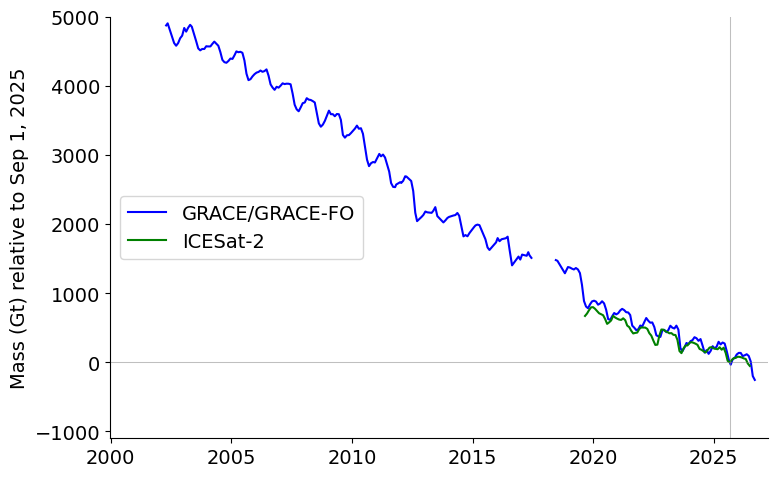

In [9]:
# Plot the full data record (2002-2026) from GRACE/FO and ICESat-2

fig, ax = plt.subplots(figsize=(8,5))
# GRACE (showing gap between eras)
era1 = gdate < datetime(2017, 6, 15)
era2 = gdate > datetime(2018, 6, 1) 
ax.plot(gdate[era1], gmb[era1], color='blue', label='GRACE/GRACE-FO')
ax.plot(gdate[era2], gmb[era2], color='blue')
# ICESat-2
ax.plot(IS_date, IS_mb, color='green', label='ICESat-2')
stfoo = startdate.strftime("%b ") + str(startdate.day) + ", " + startdate.strftime("%Y")
ax.set_ylabel('Mass (Gt) relative to ' + stfoo)
ax.legend(loc='center left')

# Add a zero line
plt.axhline(y=0, color='gray', linewidth=0.75, alpha=0.5)
plt.axvline(x=pd.Timestamp(startdate), color='gray', linewidth=0.75, alpha=0.5)

# Axis limits
plt.gca().set_ylim([-1100,5000])
xx = plt.gca().get_xlim()
plt.gca().set_xlim([xx[0]-850, xx[-1]+200]) # 200 days after enddate
# xtick labels
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Nuke part of the box
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Ensure text or axes won't cut off on save
plt.tight_layout()

plt.savefig('MassBalance-GRACE-ICESat2-allhistory.png')
plt.savefig('MassBalance-GRACE-ICESat2-allhistory.svg')

plt.show()

In [10]:
# GRACE long-term trend - Split into two periods to avoid the gap in 2017-18

from scipy.stats import linregress

def period_trend(date, mb, start, end):
    mask = (date >= start) & (date <= end)
    t = date[mask]
    ordinal = t.astype('datetime64[D]').astype(int)
    yrs = (ordinal - ordinal[0]) / 365.25
    slope, intercept, r, p, stderr = linregress(yrs, mb[mask])
    return slope, stderr, len(yrs)

# Regression over two periods
slope1, err1, n1 = period_trend(gdate, gmb, datetime(2002,1,1), datetime(2017,12,31))
slope2, err2, n2 = period_trend(gdate, gmb, datetime(2018,1,1), datetime(2026,12,31))

# Weighted average of the slopes and error propagation
wtrend = (n1*slope1 + n2*slope2)/(n1+n2)
werr = np.sqrt((n1 * err1)**2 + (n2 * err2)**2) / (n1 + n2)

print(f'Trend over the full GRACE / GRACE-FO record: {wtrend:.1f} Gt/yr')

Trend over the full GRACE / GRACE-FO record: -211.0 Gt/yr


In [11]:
# Spaghetti plot function
def spaghetti_plot(years, dates, mb, err, end_month, end_day, report_day, color, label):
    
    for yr in years:
        tl = mb_year_timeline(yr, 8, 31, report_day)
        mbi, erri = interp_mb(tl, dates, mb, err)
        #erri = erri-erri[0]
        days = np.array([(d - tl[0]).days for d in tl])
        lw = 4 if yr == years[-1] else 0.5
        
        # Only label the most recent year
        if yr == years[-1]:
            # last non-NaN element
            valid = np.flatnonzero(~np.isnan(mbi))
            mb_last = mbi[valid[-1]]
            err_last = erri[valid[-1]]
            plot_label = (f'{label}: {mb_last:.0f} ± {err_last:.0f} Gt')
        else:
            plot_label = None
            
        plt.plot(days, mbi, color=color, linewidth=lw, label=plot_label)

    # Error envelope for last year
    plt.fill_between(days, mbi-erri, mbi+erri, alpha=0.2, linewidth=0, color=color, zorder=300)
    print(f'{yr} has mb {mbi[valid[-1]]:.1f} +/- {erri[valid[-1]]:.1f} Gt')

2026 has mb -228.2 +/- 82.7 Gt
2026 has mb -52.5 +/- 29.2 Gt


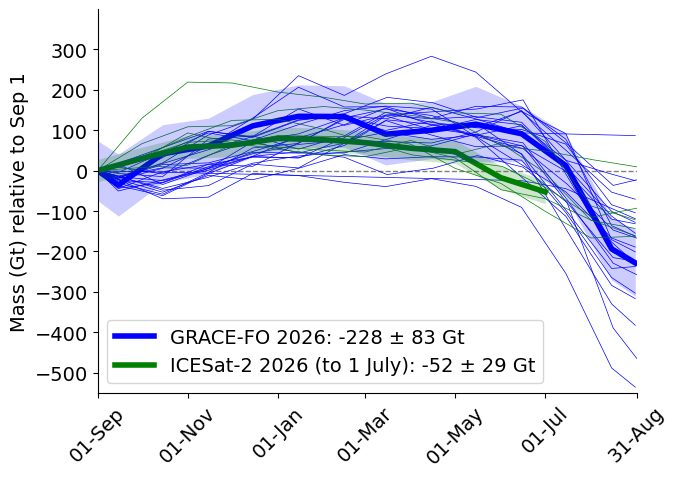

In [23]:
# Make the spaghetti plot
plt.figure(figsize=(7,5))

# Put data on plot
spaghetti_plot(range(2003,2027), gdate, gmb, g_err_noleak, 7, 16, 15, 'blue', label='GRACE-FO 2026')
spaghetti_plot(range(2020,2027), IS_date, IS_mb, IS_err, 7, 2, 1, 'green', label='ICESat-2 2026 (to 1 July)')

# Tick management
xtick = np.cumsum([0, 30, 31, 30, 31, 31, 28, 31, 30, 31, 30, 31, 31]) * 1    # plot units are in days
xtick = xtick[[0, 2, 4, 6, 8, 10, 12]]
plt.xticks(xtick, ['01-Sep', '01-Nov', '01-Jan', '01-Mar', '01-May', '01-Jul', '31-Aug'])

plt.ylabel('Mass (Gt) relative to Sep 1')
plt.legend(loc='lower left')

# Nuke part of the box
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add a zero line
plt.axhline(y=0, color='gray', linestyle='--', linewidth=1, zorder=1)

plt.xticks(rotation=45)
plt.ylim(-550, 400)
plt.yticks(np.arange(-500,300+1,100))

# Ensure text or axes won't cut off on save
plt.tight_layout()

plt.savefig('MassBalance-GRACE-ICESat2-spaghetti.png')
plt.savefig('MassBalance-GRACE-ICESat2-spaghetti.svg')

plt.show()

In [14]:
# YTD climatology
def partial_year_mb(years, dates, mb, end_month, end_day, report_day):
    vals = []
    for yr in years:
        tl = mb_year_timeline(yr, end_month, end_day, report_day)
        mbi = interp_mb(tl, dates, mb)
        vals.append(mbi[-1])
    return np.array(vals)

In [16]:
# GRACE
currentYTD_grace = (8,31)  #(7,16)

grace_mb = partial_year_mb(np.setdiff1d(np.arange(2003,2027), [2017,2018]), gdate, gmb, *currentYTD_grace, report_day=15)

print(f'GRACE mean YTD = '
    f'{np.nanmean(grace_mb):.0f} ± '
    f'{np.nanstd(grace_mb):.0f} Gt')

GRACE mean YTD = -216 ± 125 Gt


In [43]:
# ICESat-2
currentYTD_icesat2 = (7,2)

is_mb = partial_year_mb(np.arange(2020,2027), IS_date, IS_mb, *currentYTD_icesat2, report_day=1)

print(f'ICESat-2 mean YTD = '
    f'{np.nanmean(is_mb[:-1]):.0f} ± '
    f'{np.nanstd(is_mb[:-1]):.0f} Gt')

ICESat-2 mean YTD = -18 ± 62 Gt


2003: 40 ± 65 Gt
2004: -23 ± 68 Gt
2005: 2 ± 65 Gt
2006: 0 ± 65 Gt
2007: -114 ± 65 Gt
2008: -78 ± 67 Gt
2009: 70 ± 67 Gt
2010: -155 ± 67 Gt
2011: -128 ± 74 Gt
2012: -110 ± 72 Gt
2013: 25 ± 69 Gt
2014: -94 ± 67 Gt
2015: -60 ± 70 Gt
2016: -35 ± 66 Gt
2019: -282 ± 65 Gt
2020: -67 ± 32 Gt
2021: -6 ± 33 Gt
2022: -63 ± 40 Gt
2023: 72 ± 34 Gt
2024: 62 ± 36 Gt
2025: -5 ± 36 Gt
2026: -23 ± 42 Gt
Climatology: -45 ± 84 Gt


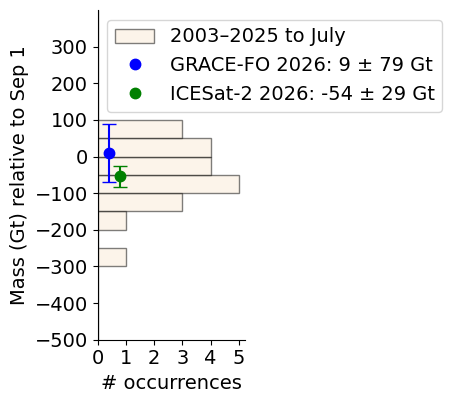

In [261]:
# Histogram for years through July only
# -------------------------------------------------------------
# Create the climatology
# -------------------------------------------------------------

graceYTD   = (7, 16)
icesatYTD  = (7, 2)

mbbyyr = []
errbyyr = []

grace2026_mb = np.nan
grace2026_err = np.nan

is2026_mb = np.nan
is2026_err = np.nan

yrstouse = np.concatenate((np.arange(2003, 2017), np.arange(2019, 2027)))

for yr in yrstouse:

    mbvals = []
    errvals = []

    # ---------------------------------------------------------
    # GRACE / GRACE-FO
    # ---------------------------------------------------------

    if yr not in [2017, 2018]:

        tl = mb_year_timeline(yr, graceYTD[0], graceYTD[1], report_day=15)
        mbG, errG = interp_mb(tl, gdate, gmb, g_err_noleak)
        valid = np.flatnonzero(~np.isnan(mbG))
        mbvals.append(mbG[valid[-1]])
        errvals.append(errG[valid[-1]])
        if yr == 2026:
            grace2026_mb  = mbG[valid[-1]]
            grace2026_err = errG[valid[-1]]

    # ---------------------------------------------------------
    # ICESat-2
    # ---------------------------------------------------------

    if yr >= 2020:

        tl = mb_year_timeline(yr, icesatYTD[0], icesatYTD[1], report_day=1)
        mbI, errI = interp_mb(tl, IS_date, IS_mb, IS_err)
        valid = np.flatnonzero(~np.isnan(mbI))
        mbvals.append(mbI[valid[-1]])
        errvals.append(errI[valid[-1]])
        if yr == 2026:
            is2026_mb  = mbI[valid[-1]]
            is2026_err = errI[valid[-1]]

    # ---------------------------------------------------------
    # Average 
    # ---------------------------------------------------------

    mbavg = np.nanmean(mbvals)

    # combine uncertainties in quadrature
    if len(errvals) > 0:
        erravg = np.sqrt(np.sum(np.array(errvals)**2)) / len(errvals)
    else:
        erravg = np.nan

    mbbyyr.append(mbavg)
    errbyyr.append(erravg)

    print(f'{yr}: {mbavg:.0f} ± {erravg:.0f} Gt')

mbbyyr = np.array(mbbyyr)
errbyyr = np.array(errbyyr)

print(f'Climatology: '
    f'{np.nanmean(mbbyyr[:-1]):.0f} ± '
    f'{np.nanstd(mbbyyr[:-1]):.0f} Gt' )




# -------------------------------------------------------------
# Histogram for years going through July only
# -------------------------------------------------------------

plt.figure(figsize=(3.5, 4.25))
binedges = np.arange(-500, 401, 50)

# Histogram for 2003-2025
plt.hist(mbbyyr[:-1], bins=binedges, orientation='horizontal', color='antiquewhite', edgecolor='black', alpha=0.5, linewidth=1, label='2003–2025 to July')

# 2026 GRACE-FO
plt.plot(0.4, grace2026_mb, 'b.', markersize=15, label=f'GRACE-FO 2026: {grace2026_mb:.0f} ± {grace2026_err:.0f} Gt')
plt.errorbar(0.4, grace2026_mb, yerr=grace2026_err, fmt='none', ecolor='b', capsize=5)

# 2026 ICESat-2
plt.plot(0.8, is2026_mb, 'g.', markersize=15, label=f'ICESat-2 2026: {is2026_mb:.0f} ± {is2026_err:.0f} Gt')
plt.errorbar(0.8, is2026_mb, yerr=is2026_err, fmt='none', ecolor='g', capsize=5)

plt.xticks(np.arange(6))
plt.yticks(np.arange(-500, 301, 100))
plt.xlim(0, 5.2)

plt.ylabel('Mass (Gt) relative to Sep 1')
plt.xlabel('# occurrences')

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.legend()
plt.tight_layout()



plt.savefig('MassBalanceHistogram-YTD-July2026.png')
plt.savefig('MassBalanceHistogram-YTD-July2026.svg')

plt.show()

Full-year mass balance 2003: -67 ± 67 Gt
Full-year mass balance 2004: -157 ± 73 Gt
Full-year mass balance 2005: -224 ± 66 Gt
Full-year mass balance 2006: -141 ± 66 Gt
Full-year mass balance 2007: -298 ± 65 Gt
Full-year mass balance 2008: -251 ± 66 Gt
Full-year mass balance 2009: -166 ± 67 Gt
Full-year mass balance 2010: -390 ± 66 Gt
Full-year mass balance 2011: -320 ± 71 Gt
Full-year mass balance 2012: -488 ± 80 Gt
Full-year mass balance 2013: -11 ± 67 Gt
Full-year mass balance 2014: -231 ± 65 Gt
Full-year mass balance 2015: -187 ± 68 Gt
Full-year mass balance 2016: -234 ± 71 Gt
Full-year mass balance 2019: -535 ± 65 Gt
Full-year mass balance 2020: -154 ± 34 Gt
Full-year mass balance 2021: -134 ± 35 Gt
Full-year mass balance 2022: -153 ± 37 Gt
Full-year mass balance 2023: -168 ± 35 Gt
Full-year mass balance 2024: 4 ± 41 Gt
Full-year mass balance 2025: -159 ± 39 Gt

2003-2025 mean full-year mass balance: -213 ± 133 Gt


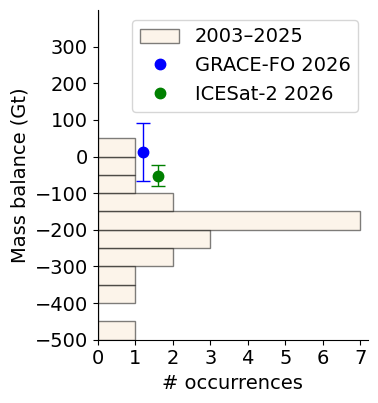

In [259]:
# Histogram for full MB years
# ===============================================================
# HISTOGRAM OF FULL MASS BALANCE YEARS
# ===============================================================
full_year_end = (8, 31)
currentYTD_grace = (7, 15)
currentYTD_is2   = (7, 1)
mbbyyr = []
errbyyr = []
yrstouse = np.concatenate((np.arange(2003, 2017), np.arange(2019, 2026)))

for yr in yrstouse:
    mbvals = []
    errvals = []

    # GRACE full year
    if yr not in [2017, 2018]:
        tl = mb_year_timeline(yr, full_year_end[0], full_year_end[1], report_day=15)
        mbG, errG = interp_mb(tl, gdate, gmb, g_err_noleak)
        valid = np.flatnonzero(~np.isnan(mbG))
        mbvals.append(mbG[valid[-1]])
        errvals.append(errG[valid[-1]])

    # ICESat-2 full year
    if yr >= 2020:
        tl = mb_year_timeline(yr, full_year_end[0], full_year_end[1], report_day=1)
        mbI, errI = interp_mb(tl, IS_date, IS_mb, IS_err)
        valid = np.flatnonzero(~np.isnan(mbI))
        mbvals.append(mbI[valid[-1]])
        errvals.append(errI[valid[-1]])

    # Average available datasets
    mbavg = np.nanmean(mbvals)
    erravg = (np.sqrt(np.sum(np.array(errvals)**2)) / len(errvals))
    mbbyyr.append(mbavg)
    errbyyr.append(erravg)

    print(f'Full-year mass balance {yr}: {mbavg:.0f} ± {erravg:.0f} Gt')

mbbyyr = np.array(mbbyyr)
errbyyr = np.array(errbyyr)

print('')
print(f'2003-2025 mean full-year mass balance: '
    f'{np.mean(mbbyyr):.0f} ± {np.std(mbbyyr):.0f} Gt')

# ===============================================================
# 2026 YEAR-TO-DATE VALUES
# ===============================================================

# GRACE
tl = mb_year_timeline(2026, currentYTD_grace[0], currentYTD_grace[1], report_day=15)
mbG2026, errG2026 = interp_mb(tl, gdate, gmb, g_err_noleak)
valid = np.flatnonzero(~np.isnan(mbG2026))
grace2026_mb  = mbG2026[valid[-1]]
grace2026_err = errG2026[valid[-1]]

# ICESat-2
tl = mb_year_timeline(2026, currentYTD_is2[0], currentYTD_is2[1], report_day=1)
mbI2026, errI2026 = interp_mb(tl, IS_date, IS_mb, IS_err)
valid = np.flatnonzero(~np.isnan(mbI2026))
is2026_mb  = mbI2026[valid[-1]]
is2026_err = errI2026[valid[-1]]

# ===============================================================
# HISTOGRAM
# ===============================================================

plt.figure(figsize=(4.0, 4.25))
binedges = np.arange(-500, 401, 50)
plt.hist(mbbyyr, orientation='horizontal', color='antiquewhite', edgecolor='black', bins=binedges, alpha=0.5, linewidth=1, label='2003–2025')

# 2026 GRACE
plt.plot(1.2, grace2026_mb, 'b.', markersize=15, label=f'GRACE-FO 2026')#: {grace2026_mb:.0f} ± {grace2026_err:.0f} Gt')
plt.errorbar(1.2, grace2026_mb, yerr=grace2026_err, fmt='none', ecolor='b', capsize=5, linewidth=1)

# 2026 ICESat-2
plt.plot(1.6, is2026_mb, 'g.', markersize=15, label=f'ICESat-2 2026')#: {is2026_mb:.0f} ± {is2026_err:.0f} Gt')
plt.errorbar(1.6, is2026_mb, yerr=is2026_err, fmt='none', ecolor='g', capsize=5, linewidth=1)

# Plot formatting
plt.xticks(np.arange(8))
plt.yticks(np.arange(-500, 301, 100))
plt.xlim(0, 7.2)
plt.ylabel('Mass balance (Gt)')
plt.xlabel('# occurrences')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.legend()
plt.tight_layout()


plt.savefig('MassBalanceHistogram-FullMByr-July2026.png')
plt.savefig('MassBalanceHistogram-FullMByr-July2026.svg')

plt.show()